In [1]:

import pickle
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
import matplotlib.pyplot as plt
import numpy as np
import mne
import time
from sklearn.manifold import MDS
from scipy.stats import pearsonr



In [2]:
def load_avalanche_data(filepath, min_time_length=1, max_time_length=None):
    """
    Load avalanche data from pickle file
    
    Args:
        filepath: path to the pickle file
        min_time_length: minimum temporal length required (default: 15)
        max_time_length: maximum temporal length allowed (default: None, no upper limit)
    
    Returns:
        avalanche_arrays: list of avalanche arrays with temporal length in [min_time_length, max_time_length]
    """
    with open(filepath, 'rb') as f:
        avalanches = pickle.load(f)
    
    print(f"Loaded {len(avalanches)} participants")
    
    # Extract arrays from ALL participants  
    avalanche_arrays = []
    filtered_count_too_short = 0
    filtered_count_too_long = 0
    
    for participant_idx, participant_avalanches in enumerate(avalanches):
        for avalanche_idx, avalanche in enumerate(participant_avalanches):
            # avalanche is already a numpy array, not a list
            if hasattr(avalanche, 'shape') and avalanche.ndim == 2:
                temporal_length = avalanche.shape[1]
                
                # Check temporal length constraints
                if temporal_length < min_time_length:
                    filtered_count_too_short += 1
                elif max_time_length is not None and temporal_length > max_time_length:
                    filtered_count_too_long += 1
                else:
                    avalanche_arrays.append(avalanche)
                    if participant_idx == 0 and len(avalanche_arrays) <= 3:  # Debug first few
                        print(f"  Added avalanche {avalanche_idx}: shape {avalanche.shape}")
    
    print(f"Total avalanches extracted: {len(avalanche_arrays)}")
    print(f"Filtered out {filtered_count_too_short} avalanches with temporal length < {min_time_length}")
    if max_time_length is not None:
        print(f"Filtered out {filtered_count_too_long} avalanches with temporal length > {max_time_length}")
    
    return avalanche_arrays

In [3]:
avalanche_arrays = load_avalanche_data('processed_avalanches_250Hz/filtered_avalanche_peaks_250hz_twopoles.pkl', min_time_length=11,max_time_length=None)
avalanche_arrays.extend([-arr for arr in avalanche_arrays])



Loaded 429 participants
  Added avalanche 0: shape (64, 11)
  Added avalanche 1: shape (64, 13)
  Added avalanche 2: shape (64, 11)
Total avalanches extracted: 5108
Filtered out 0 avalanches with temporal length < 11


In [4]:
import pickle
import numpy as np

def link_avalanches_to_datasets(all_avalanches, all_avalanche_times, file_metadata):
    """
    Link each avalanche to its dataset labels and temporal information.
    
    Parameters:
    -----------
    all_avalanches : list of lists
        List containing avalanche lists for each dataset. Each inner list contains
        avalanche matrices
    all_avalanche_times : list of lists
        List containing avalanche timing lists for each dataset. Each inner list contains
        tuples of (start_idx, end_idx) indicating when each avalanche occurs
    file_metadata : list of dicts
        List of metadata dictionaries for each dataset
    
    Returns:
    --------
    avalanche_dataset_links : list of dicts
        List of dictionaries, each containing avalanche metadata and timing info
    """
    
    if len(all_avalanches) != len(all_avalanche_times):
        raise ValueError(f"Number of avalanche lists ({len(all_avalanches)}) must match "
                        f"number of timing lists ({len(all_avalanche_times)})")
    
    if len(all_avalanches) != len(file_metadata):
        raise ValueError(f"Number of avalanche lists ({len(all_avalanches)}) must match "
                        f"number of metadata entries ({len(file_metadata)})")
    
    avalanche_dataset_links = []
    
    for dataset_idx, (dataset_avalanches, dataset_times, metadata) in enumerate(
            zip(all_avalanches, all_avalanche_times, file_metadata)):
        
        if len(dataset_avalanches) != len(dataset_times):
            raise ValueError(f"Dataset {dataset_idx}: Number of avalanches "
                           f"({len(dataset_avalanches)}) must match number of timing entries "
                           f"({len(dataset_times)})")
        
        for avalanche_idx, (avalanche, avalanche_time) in enumerate(
                zip(dataset_avalanches, dataset_times)):
            
            start_time, end_time = avalanche_time
            duration = end_time - start_time
            
            link = {
                'avalanche_id': f"dataset_{dataset_idx}_avalanche_{avalanche_idx}",
                'drug_condition': metadata['drug_condition'],  # Psilocybin/Control
                'task': metadata['task'],  # Meditation/Music/Resting state/Video
                'is_trained': metadata['is_trained'],  # True/False
                'start_time': start_time,  # Start index in original dataset
                'end_time': end_time,  # End index in original dataset
                'duration': duration  # Duration in time steps
            }
            avalanche_dataset_links.append(link)
    
    return avalanche_dataset_links

# Load the metadata
print("Loading metadata...")
with open('/home/novicky/clean_code/clusters/metadata.pkl', 'rb') as f:
    file_metadata = pickle.load(f)

file_metadata.extend(file_metadata)  # Duplicate for negative avalanches

# Load the filtered avalanches
print("Loading filtered avalanches...")
with open('processed_avalanches_250Hz/filtered_avalanche_peaks_250hz_twopoles.pkl', 'rb') as f:
    filtered_avalanches = pickle.load(f)

filtered_avalanches.extend(filtered_avalanches)  # Duplicate for negative avalanches

# Load the filtered avalanche times
print("Loading filtered avalanche times...")
with open('processed_avalanches_250Hz/filtered_avalanche_times_250hz_twopoles.pkl', 'rb') as f:
    filtered_avalanche_times = pickle.load(f)

filtered_avalanche_times.extend(filtered_avalanche_times)  # Duplicate for negative avalanches

print(f"Loaded {len(file_metadata)} datasets metadata")
print(f"Loaded {len(filtered_avalanches)} dataset avalanche lists")

# Link avalanches to datasets
print("Linking avalanches to datasets...")
avalanche_links = link_avalanches_to_datasets(filtered_avalanches, filtered_avalanche_times, file_metadata)

# Save the links
output_file = 'processed_avalanches_250Hz/avalanche_dataset_links.pkl'
with open(output_file, 'wb') as f:
    pickle.dump(avalanche_links, f)

print(f"Saved {len(avalanche_links)} avalanche-dataset links to {output_file}")

# Print some statistics
total_avalanches = len(avalanche_links)
drug_counts = {}
task_counts = {}
trained_counts = {}

for link in avalanche_links:
    drug = link['drug_condition']
    task = link['task']
    trained = link['is_trained']
    
    drug_counts[drug] = drug_counts.get(drug, 0) + 1
    task_counts[task] = task_counts.get(task, 0) + 1
    trained_counts[trained] = trained_counts.get(trained, 0) + 1

print(f"\nSummary of {total_avalanches} avalanches:")
print(f"By drug condition: {drug_counts}")
print(f"By task: {task_counts}")
print(f"By training status: {trained_counts}")

Loading metadata...
Loading filtered avalanches...
Loading filtered avalanche times...
Loaded 858 datasets metadata
Loaded 858 dataset avalanche lists
Linking avalanches to datasets...
Saved 10216 avalanche-dataset links to processed_avalanches_250Hz/avalanche_dataset_links.pkl

Summary of 10216 avalanches:
By drug condition: {'Control': 6238, 'Psilocybin': 3978}
By task: {'Meditation': 2950, 'Music': 3434, 'Resting state': 2460, 'Video': 1372}
By training status: {False: 4868, True: 5348}


In [5]:
# # Load the files
# with open('/home/novicky/clean_code/similarity_blocks/my_treasure/avalanche_similarity_full_matrix.pkl', 'rb') as f:
#     avalanche_similarity = pickle.load(f)

# with open('/home/novicky/clean_code/similarity_blocks/my_treasure/avalanche_paths_full_matrix.pkl', 'rb') as f:
#     avalanche_paths = pickle.load(f)

# Load the files
with open('/home/novicky/clean_code/similarity_blocks_with_polarity/similarity_matrix.pkl', 'rb') as f:
    avalanche_similarity = pickle.load(f)

with open('/home/novicky/clean_code/similarity_blocks_with_polarity/path_matrix.pkl', 'rb') as f:
    avalanche_paths = pickle.load(f)

print("Loaded files:")
print(f"avalanche_similarity shape: {avalanche_similarity.shape}, dtype: {avalanche_similarity.dtype}")
print(f"avalanche_paths shape: {avalanche_paths.shape}, dtype: {avalanche_paths.dtype}")


Loaded files:
avalanche_similarity shape: (10216, 10216), dtype: float32
avalanche_paths shape: (10216, 10216), dtype: object


In [6]:

def build_consensus_alignment(cluster_id, clusters, avalanche_arrays, avalanche_paths, similarity_clean, verbose = False):
    """
    Build consensus alignment using the medoid as reference timeline (Option A).
    
    Approach:
    1. Finds the medoid (most central avalanche)
    2. Uses the medoid's timeline as the consensus timeline
    3. Warps each avalanche to the medoid using DTW paths
    4. Averages all warped avalanches
    
    Benefits:
    - Clear reference timeline (medoid)
    - Direct use of DTW alignment
    - No gaps in consensus
    
    Drawbacks:
    - Loses activity before/after aligned regions
    - May compress/expand temporal details
    """
    # Get all avalanches in this cluster
    cluster_indices = np.where(clusters == cluster_id)[0]
    n_in_cluster = len(cluster_indices)
    
    print(f"\n{'='*60}")
    print(f"Cluster {cluster_id}: {n_in_cluster} avalanches")
    print(f"Avalanche indices: {cluster_indices}")
    print(f"{'='*60}")
    
    # Step 1: Find medoid (most central avalanche)
    cluster_distances = similarity_clean[np.ix_(cluster_indices, cluster_indices)]
    sum_distances = cluster_distances.sum(axis=1)
    medoid_idx_in_cluster = np.argmin(sum_distances)
    medoid_idx = cluster_indices[medoid_idx_in_cluster]
    
    medoid_array = avalanche_arrays[medoid_idx]
    medoid_length = medoid_array.shape[1]
    n_channels = medoid_array.shape[0]
    
    print(f"\nMedoid: avalanche {medoid_idx}")
    print(f"  Shape: {medoid_array.shape}")
    print(f"  Length: {medoid_length} time steps")
    print(f"  Avg distance to others: {sum_distances[medoid_idx_in_cluster] / max(1, n_in_cluster - 1):.3f}")
    
    # Step 2: Initialize consensus timeline (same length as medoid)
    # We'll accumulate warped avalanches and count how many contribute at each time point
    consensus_sum = np.zeros((n_channels, medoid_length))
    consensus_count = np.zeros(medoid_length)  # Track how many avalanches contribute at each time
    
    # Store individual aligned avalanches for return
    aligned_avalanches = []
    alignment_info = {}  # Store alignment details for each avalanche
    
    print(f"\n{'='*60}")
    print("Warping avalanches to medoid timeline...")
    print(f"{'='*60}")
    
    # Step 3: Process each avalanche
    for idx in cluster_indices:
        # Medoid maps to itself (identity mapping)
        if idx == medoid_idx:
            aligned = medoid_array.copy()
            consensus_sum += aligned
            consensus_count += 1
            aligned_avalanches.append(aligned)
            
            alignment_info[idx] = {
                'is_medoid': True,
                'frames_used': medoid_length,
                'frames_lost_start': 0,
                'frames_lost_end': 0
            }
            
            print(f"  Avalanche {idx} (medoid): identity mapping")
            continue
        
        # Get the DTW path between idx and medoid
        i_min, i_max = min(idx, medoid_idx), max(idx, medoid_idx)
        
        try:
            path_list = avalanche_paths[i_min][i_max]
            
            # Extract the actual path
            if isinstance(path_list, list) and len(path_list) > 0:
                path = path_list[0]
            else:
                print(f"  ⚠️  Avalanche {idx}: Empty path, skipping")
                continue
            
            if len(path) == 0:
                print(f"  ⚠️  Avalanche {idx}: No path to medoid, skipping")
                continue
                
        except (IndexError, TypeError) as e:
            print(f"  ⚠️  Avalanche {idx}: Error accessing path - {e}")
            continue
        
        # Step 4: Extract frame correspondences from path
        # path is stored as (i_min, i_max), so we need to figure out which is which
        if idx < medoid_idx:
            # Path stored as (idx, medoid)
            idx_times = np.array([p[0] for p in path])
            medoid_times = np.array([p[1] for p in path])
        else:
            # Path stored as (medoid, idx)
            medoid_times = np.array([p[0] for p in path])
            idx_times = np.array([p[1] for p in path])
        
        # Step 5: Warp idx to medoid's timeline
        # For each medoid time point, collect all idx frames that map to it
        avalanche_data = avalanche_arrays[idx]
        avalanche_length = avalanche_data.shape[1]
        
        # Create aligned version (same length as medoid)
        aligned = np.zeros((n_channels, medoid_length))
        
        # For each unique medoid time, average all idx frames that map to it
        for medoid_t in range(medoid_length):
            # Find all idx frames that align to this medoid frame
            matching_idx_frames = idx_times[medoid_times == medoid_t]
            
            if len(matching_idx_frames) > 0:
                # Average the idx frames that map to this medoid frame
                aligned[:, medoid_t] = avalanche_data[:, matching_idx_frames].mean(axis=1)
                consensus_count[medoid_t] += 1
        
        # Add to consensus
        consensus_sum += aligned
        aligned_avalanches.append(aligned)
        
        # Track what was lost
        frames_in_path = len(np.unique(idx_times))
        frames_lost_start = idx_times.min()
        frames_lost_end = avalanche_length - idx_times.max() - 1
        
        alignment_info[idx] = {
            'is_medoid': False,
            'original_length': avalanche_length,
            'frames_used': frames_in_path,
            'frames_lost_start': frames_lost_start,
            'frames_lost_end': frames_lost_end,
            'aligned_region': (idx_times.min(), idx_times.max()),
            'medoid_region': (medoid_times.min(), medoid_times.max())
        }

        if verbose:
        
            print(f"  Avalanche {idx} (len={avalanche_length}):")
            print(f"    Aligned frames {idx_times.min()}-{idx_times.max()} → medoid frames {medoid_times.min()}-{medoid_times.max()}")
            print(f"    Lost: {frames_lost_start} frames at start, {frames_lost_end} frames at end")
    
    # Step 6: Compute consensus average
    # Avoid division by zero
    consensus_count[consensus_count == 0] = 1
    average_avalanche = consensus_sum / consensus_count
    
    return (np.array(aligned_avalanches), 
            average_avalanche, 
            alignment_info, 
            medoid_idx,
            consensus_count)

In [7]:
def simple_hierarchical_clustering(distance_matrix, threshold=50.0, method='average', min_cluster_size=1, use_lowest_tightness=True):
    """
    Simple hierarchical clustering - the easy way!
    Returns results in same format as cluster_with_progressive_locking.
    
    Parameters:
    -----------
    distance_matrix : array, shape (n_samples, n_samples)
        Pairwise distances between samples
    threshold : float
        Distance threshold for forming clusters (default: 50.0)
    method : str
        Linkage method ('average', 'single', 'complete', 'ward')
    min_cluster_size : int
        Minimum size for a cluster (smaller clusters assigned to -1)
        
    Returns:
    --------
    cluster_assignments : array
        Cluster ID for each sample (-1 for noise/small clusters, 0+ for clusters)
    cluster_info : list of dict
        Information about each cluster (compatible with original format)
    """
    
    # Convert distance matrix to condensed form for scipy
    condensed_distances = squareform(distance_matrix, checks=False)
    
    # Perform hierarchical clustering
    linkage_matrix = linkage(condensed_distances, method=method)
    
    # Cut the dendrogram at the specified threshold
    temp_clusters = fcluster(linkage_matrix, t=threshold, criterion='distance')
    
    # Convert to 0-based indexing (scipy uses 1-based)
    temp_clusters = temp_clusters - 1
    
    # Filter out small clusters (assign them to -1)
    cluster_assignments = -np.ones(len(temp_clusters), dtype=int)
    cluster_info = []
    cluster_counter = 0
    
    unique_clusters = np.unique(temp_clusters)
    
    print(f"=== SIMPLE HIERARCHICAL CLUSTERING ===")
    print(f"Method: {method}")
    print(f"Threshold: {threshold}")
    print(f"Min cluster size: {min_cluster_size}")
    
    for cluster_id in unique_clusters:
        cluster_mask = temp_clusters == cluster_id
        cluster_indices = np.where(cluster_mask)[0]
        cluster_size = len(cluster_indices)
        
        if cluster_size >= min_cluster_size:
            # Keep this cluster
            cluster_assignments[cluster_mask] = cluster_counter
            
            # Compute tightness (average intra-cluster distance)
            if cluster_size > 1:
                sub_matrix = distance_matrix[np.ix_(cluster_indices, cluster_indices)]
                triu_indices = np.triu_indices(cluster_size, k=1)
                tightness = np.mean(sub_matrix[triu_indices])
            else:
                tightness = 0.0
            
            cluster_info.append({
                'cluster_id': cluster_counter,
                'size': cluster_size,
                'tightness': tightness,
                'locked_at_threshold': threshold  # For compatibility
            })
            
            print(f"  Cluster {cluster_counter}: size={cluster_size}, tightness={tightness:.2f}")
            cluster_counter += 1
        else:
            print(f"  Discarded small cluster: size={cluster_size} (< {min_cluster_size})")
    
    # Sort clusters by tightness (lower = tighter/better clusters)
    if use_lowest_tightness:
        cluster_info.sort(key=lambda x: x['tightness'])
    
    n_noise = np.sum(cluster_assignments == -1)
    print(f"\nSummary (sorted by tightness):")
    print(f"  Total clusters: {len(cluster_info)}")
    print(f"  Unassigned/noise: {n_noise}")
    print(f"  Tightest cluster: {cluster_info[0]['tightness']:.3f}" if cluster_info else "  No clusters found")
    print(f"  Loosest cluster: {cluster_info[-1]['tightness']:.3f}" if cluster_info else "")
    
    return cluster_assignments, cluster_info

In [62]:
import numpy as np
import matplotlib.pyplot as plt
import mne
from mne.channels import make_dig_montage
import json
from matplotlib.ticker import MaxNLocator


def plot_cluster_average(cluster_id, clusters, avalanche_arrays, average, medoid_idx, 
                        electrode_positions_file, plot_individuals=False,saveit=False):
    """Plot the consensus average (aligned to medoid) from a cluster using custom electrode positions."""
    
    # Get cluster indices
    cluster_indices = np.where(clusters == cluster_id)[0]
    
    print(f"\nCluster {cluster_id} - Building consensus average from {len(cluster_indices)} avalanches")
    
    # # Build consensus alignment (this aligns all avalanches to medoid and averages them)
    # aligned, average, alignment_info, medoid_idx, consensus_count = build_consensus_alignment(
    #     cluster_id=cluster_id,
    #     clusters=clusters,
    #     avalanche_arrays=avalanche_arrays,
    #     avalanche_paths=avalanche_paths,
    #     similarity_clean=avalanche_similarity
    # )
    
    # Get average data
    n_electrodes, n_timepoints = average.shape
    
    print(f"  Medoid: avalanche {medoid_idx}")
    print(f"  Average shape: {average.shape}")
    
    # Load custom electrode positions
    with open(electrode_positions_file, 'r') as f:
        electrode_data = json.load(f)
    
    channels = list(electrode_data.keys())
    
    # Create custom montage
    ch_pos = {}
    for ch in channels:
        pos = electrode_data[ch]
        ch_pos[ch] = [pos['x'], pos['y'], pos['z']]
    
    montage = make_dig_montage(ch_pos=ch_pos, coord_frame='head')
    
    # Setup MNE info
    info = mne.create_info(ch_names=channels[:n_electrodes], sfreq=250, ch_types='eeg')
    
    # Plot the consensus average
    evoked = mne.EvokedArray(average, info)
    evoked.set_montage(montage)
    times = np.arange(n_timepoints) / 250.0
    
    # Adaptive vlim for consensus average
    data_max = np.max(np.abs(average))
    vlim = (-1, 1)
    
    fig = evoked.plot_topomap(
        times=times,
        show=False,
        ncols=6,
        nrows='auto',
        size=1.5,
        vlim=vlim,
        units='',
        image_interp='linear',
        scalings=1,
        cmap='RdBu_r',
        res=256,
        extrapolate='head',
        outlines='head',
        contours=0,
        sensors=False,
        sphere='auto'
    )


    cbar_ax = fig.axes[-1]  # Get the last axis (colorbar)
    cbar_ax.set_yticks([-1, 0, 1])
    cbar_ax.set_yticklabels(['-1', '0', '1'], fontsize=14)
    # cbar_ax.set_ylabel('Activity', fontsize=14)  # Directly set with fontsize
    
    plt.show()

    if saveit:
        fig.savefig(f'cluster_{cluster_id}_consensus_average_smooth.pdf', dpi=300)
        print(f"Saved consensus average figure for cluster {cluster_id}.")
    
    # Optionally plot all individual avalanches
    if plot_individuals:
        print(f"\nPlotting all {len(cluster_indices)} individual avalanches from cluster {cluster_id}...")
        
        for i, idx in enumerate(cluster_indices):
            avalanche_data = avalanche_arrays[idx]
            
            # Handle potential shape differences
            if avalanche_data.shape[0] != n_electrodes:
                print(f"  Skipping avalanche {idx}: electrode count mismatch ({avalanche_data.shape[0]} vs {n_electrodes})")
                continue
            
            # Create evoked object for this avalanche
            n_timepoints_ind = avalanche_data.shape[1]
            times_ind = np.arange(n_timepoints_ind) / 250.0
            
            info_ind = mne.create_info(ch_names=channels[:n_electrodes], sfreq=250, ch_types='eeg')
            evoked_ind = mne.EvokedArray(avalanche_data, info_ind)
            evoked_ind.set_montage(montage)
            
            # Adaptive vlim for individual avalanche
            data_max_ind = np.max(np.abs(avalanche_data))
            vlim_ind = (-1,1)   #(-data_max_ind, data_max_ind) if data_max_ind > 0 else (-1, 1)
            
            # Plot this individual avalanche
            fig_ind = evoked_ind.plot_topomap(
                times=times_ind,
                show=False,
                ncols=10,
                nrows='auto',
                size=2.5,
                vlim=vlim_ind,
                units='Activity',
                image_interp='linear',
                scalings=1,
                cmap='RdBu_r',
                res=256,
                extrapolate='head',
                outlines='head',
                contours=0,
                sensors='k',
                sphere='auto'
            )
            
            medoid_marker = " (MEDOID)" if idx == medoid_idx else ""
            # fig_ind.suptitle(f'Cluster {cluster_id} - Avalanche {idx}{medoid_marker} ({i+1}/{len(cluster_indices)})', 
            #              fontsize=12, fontweight='bold')
            plt.show()

In [9]:
def analyze_metadata_statistics(file_metadata, avalanche_links):
    """
    Analyze metadata statistics with detailed percentages.
    """
    print("\n=== METADATA ANALYSIS ===")
    
    # Total datasets and avalanches
    total_datasets = len(file_metadata)
    total_avalanches = len(avalanche_links)
    
    print(f"Total datasets: {total_datasets}")
    print(f"Total avalanches: {total_avalanches}")
    print(f"Average avalanches per dataset: {total_avalanches/total_datasets:.2f}")
    
    # Count avalanches by categories
    drug_counts = {}
    task_counts = {}
    trained_counts = {}
    combined_counts = {}
    
    for link in avalanche_links:
        drug = link['drug_condition']
        task = link['task']
        trained = link['is_trained']
        combined_key = f"{drug}_{task}_{'Trained' if trained else 'Untrained'}"
        
        drug_counts[drug] = drug_counts.get(drug, 0) + 1
        task_counts[task] = task_counts.get(task, 0) + 1
        trained_counts[trained] = trained_counts.get(trained, 0) + 1
        combined_counts[combined_key] = combined_counts.get(combined_key, 0) + 1
    
    # Print drug condition statistics
    print(f"\n--- BY DRUG CONDITION ---")
    for drug, count in drug_counts.items():
        percentage = (count / total_avalanches) * 100
        print(f"{drug}: {count} avalanches ({percentage:.1f}%)")
    
    # Print task statistics
    print(f"\n--- BY TASK ---")
    for task, count in sorted(task_counts.items()):
        percentage = (count / total_avalanches) * 100
        print(f"{task}: {count} avalanches ({percentage:.1f}%)")
    
    # Print training status statistics
    print(f"\n--- BY TRAINING STATUS ---")
    for trained, count in trained_counts.items():
        status = "Trained" if trained else "Untrained"
        percentage = (count / total_avalanches) * 100
        print(f"{status}: {count} avalanches ({percentage:.1f}%)")
    
    # Print detailed breakdown
    print(f"\n--- DETAILED BREAKDOWN ---")
    for combo, count in sorted(combined_counts.items()):
        percentage = (count / total_avalanches) * 100
        print(f"{combo}: {count} avalanches ({percentage:.1f}%)")
    
    # Within-drug-condition breakdown
    print(f"\n--- WITHIN DRUG CONDITIONS ---")
    for drug in ['Control', 'Psilocybin']:
        if drug in drug_counts:
            drug_total = drug_counts[drug]
            print(f"\nWithin {drug} ({drug_total} total avalanches):")
            
            # Tasks within this drug condition
            drug_task_counts = {}
            drug_trained_counts = {True: 0, False: 0}
            
            for link in avalanche_links:
                if link['drug_condition'] == drug:
                    task = link['task']
                    trained = link['is_trained']
                    drug_task_counts[task] = drug_task_counts.get(task, 0) + 1
                    drug_trained_counts[trained] += 1
            
            # Task breakdown within drug
            for task, count in sorted(drug_task_counts.items()):
                percentage = (count / drug_total) * 100
                print(f"  {task}: {count} avalanches ({percentage:.1f}% of {drug})")
            
            # Training breakdown within drug
            for trained, count in drug_trained_counts.items():
                status = "Trained" if trained else "Untrained"
                percentage = (count / drug_total) * 100
                print(f"  {status}: {count} avalanches ({percentage:.1f}% of {drug})")
    
    return {
        'total_datasets': total_datasets,
        'total_avalanches': total_avalanches,
        'by_drug': drug_counts,
        'by_task': task_counts, 
        'by_training': trained_counts,
        'detailed_breakdown': combined_counts
    }

In [10]:
def analyze_clusters_by_avalanche_metadata(cluster_assignments, avalanche_links):
    """
    Analyze which avalanches make up each cluster.
    Includes per-condition relative contribution (% of all avalanches for each condition)
    for drug, task, and training status.
    """
    print("\n=== CLUSTER COMPOSITION ANALYSIS ===")
    
    unique_clusters = np.unique(cluster_assignments)
    valid_clusters = unique_clusters[unique_clusters != -1]
    
    print(f"Total clusters: {len(valid_clusters)}")
    print(f"Noise points: {np.sum(cluster_assignments == -1)}")
    
    cluster_composition = {}

    # --- Compute global counts per category ---
    all_drug_counts = {}
    all_task_counts = {}
    all_trained_counts = {True: 0, False: 0}

    for link in avalanche_links:
        dataset_idx = int(link['avalanche_id'].split('_')[1])
        metadata = file_metadata[dataset_idx]
        drug = metadata['drug_condition']
        task = metadata['task']
        trained = metadata['is_trained']
        
        all_drug_counts[drug] = all_drug_counts.get(drug, 0) + 1
        all_task_counts[task] = all_task_counts.get(task, 0) + 1
        all_trained_counts[trained] = all_trained_counts.get(trained, 0) + 1

    print("\nTotal avalanches per category:")
    print("  Drugs:")
    for drug, total in all_drug_counts.items():
        print(f"    {drug}: {total}")
    print("  Tasks:")
    for task, total in all_task_counts.items():
        print(f"    {task}: {total}")
    print("  Training status:")
    for trained, total in all_trained_counts.items():
        label = "Trained" if trained else "Untrained"
        print(f"    {label}: {total}")
    
    # --- Cluster-level analysis ---
    for cluster_id in valid_clusters:
        cluster_mask = cluster_assignments == cluster_id
        cluster_indices = np.where(cluster_mask)[0]
        
        print(f"\n--- CLUSTER {cluster_id} ({len(cluster_indices)} avalanches) ---")
        
        cluster_avalanches = []
        for idx in cluster_indices:
            dataset_idx = int(avalanche_links[idx]['avalanche_id'].split('_')[1])
            metadata = file_metadata[dataset_idx]
            full_info = {**avalanche_links[idx], **metadata}
            cluster_avalanches.append(full_info)
        
        drug_counts = {}
        task_counts = {}
        trained_counts = {}
        subject_counts = {}
        
        for av in cluster_avalanches:
            drug = av['drug_condition']
            task = av['task']
            trained = av['is_trained']
            subject_number = av['subject_number']
            
            drug_counts[drug] = drug_counts.get(drug, 0) + 1
            task_counts[task] = task_counts.get(task, 0) + 1
            trained_counts[trained] = trained_counts.get(trained, 0) + 1
            subject_counts[subject_number] = subject_counts.get(subject_number, 0) + 1
        
        cluster_size = len(cluster_avalanches)
        num_subjects = len(subject_counts)
        
        # --- Subject details ---
        print(f"Subjects: {num_subjects} unique subjects")
        for subject, count in sorted(subject_counts.items()):
            pct_within = (count / cluster_size) * 100
            example = next(av for av in cluster_avalanches if av['subject_number'] == subject)
            subj_type = "Trained" if example['is_trained'] else "Untrained"
            print(f"  Subject {subject} ({subj_type}): {count} avalanches ({pct_within:.1f}%)")
        
        # --- Drug breakdown ---
        print("Drug conditions:")
        for drug, count in drug_counts.items():
            pct_within = (count / cluster_size) * 100
            pct_global = (count / all_drug_counts[drug]) * 100 if all_drug_counts[drug] > 0 else 0
            print(f"  {drug}: {count} avalanches "
                  f"({pct_within:.1f}% of cluster, {pct_global:.2f}% of all {drug} avalanches)")
        
        # --- Task breakdown ---
        print("Tasks:")
        for task, count in sorted(task_counts.items()):
            pct_within = (count / cluster_size) * 100
            pct_global = (count / all_task_counts[task]) * 100 if all_task_counts[task] > 0 else 0
            print(f"  {task}: {count} avalanches "
                  f"({pct_within:.1f}% of cluster, {pct_global:.2f}% of all {task} avalanches)")
        
        # --- Training breakdown ---
        print("Training status:")
        for trained, count in trained_counts.items():
            label = "Trained" if trained else "Untrained"
            pct_within = (count / cluster_size) * 100
            pct_global = (count / all_trained_counts[trained]) * 100 if all_trained_counts[trained] > 0 else 0
            print(f"  {label}: {count} avalanches "
                  f"({pct_within:.1f}% of cluster, {pct_global:.2f}% of all {label.lower()} avalanches)")
        
        # --- Store ---
        cluster_composition[cluster_id] = {
            'size': cluster_size,
            'num_subjects': num_subjects,
            'avalanche_indices': cluster_indices.tolist(),
            'avalanche_ids': [av['avalanche_id'] for av in cluster_avalanches],
            'subject_counts': subject_counts,
            'drug_counts': drug_counts,
            'task_counts': task_counts,
            'trained_counts': trained_counts,
            'avalanches': cluster_avalanches
        }
    
    return cluster_composition


In [11]:
# Run clustering on your avalanche data
clusters, cluster_info = simple_hierarchical_clustering(
    distance_matrix=avalanche_similarity,  # Your distance matrix
    threshold=3.5,                        # Adjust this value
    method='average',                      # or 'single', 'complete', 'ward'
    min_cluster_size=30,                    # Minimum avalanches per cluster
    use_lowest_tightness=False
)

=== SIMPLE HIERARCHICAL CLUSTERING ===
Method: average
Threshold: 3.5
Min cluster size: 30
  Discarded small cluster: size=1 (< 30)
  Discarded small cluster: size=1 (< 30)
  Discarded small cluster: size=1 (< 30)
  Discarded small cluster: size=1 (< 30)
  Discarded small cluster: size=1 (< 30)
  Discarded small cluster: size=1 (< 30)
  Discarded small cluster: size=1 (< 30)
  Discarded small cluster: size=1 (< 30)
  Discarded small cluster: size=1 (< 30)
  Discarded small cluster: size=1 (< 30)
  Discarded small cluster: size=1 (< 30)
  Discarded small cluster: size=1 (< 30)
  Discarded small cluster: size=1 (< 30)
  Discarded small cluster: size=1 (< 30)
  Discarded small cluster: size=1 (< 30)
  Discarded small cluster: size=1 (< 30)
  Discarded small cluster: size=1 (< 30)
  Discarded small cluster: size=1 (< 30)
  Discarded small cluster: size=1 (< 30)
  Discarded small cluster: size=1 (< 30)
  Discarded small cluster: size=1 (< 30)
  Discarded small cluster: size=1 (< 30)
  Disca

In [13]:
# Plot all clusters (they're already sorted by tightness - best first)
cluster_averages = []
cluster_medoids = []
cluster_focus = cluster_info
for i, info in enumerate(cluster_info):
    cluster_id = info['cluster_id']

    aligned, average, alignment_info, medoid_idx, consensus_count = build_consensus_alignment(
        cluster_id=cluster_id,
        clusters=clusters,
        avalanche_arrays=avalanche_arrays,
        avalanche_paths=avalanche_paths,
        similarity_clean=avalanche_similarity
    )
    cluster_averages.append(average)
    cluster_medoids.append(medoid_idx)

# Remove highly negatively correlated clusters based on aligned averages
to_remove = set()
for i, info_i in enumerate(cluster_info):
    for j in range(i+1, len(cluster_info)):
        info_j = cluster_info[j]
        if cluster_averages[i].size == cluster_averages[j].size:
            corr = pearsonr(cluster_averages[i].flatten(), cluster_averages[j].flatten())[0]
            if corr < -0.999:
                to_remove.add(info_i['cluster_id'] if info_i['tightness'] > info_j['tightness'] else info_j['cluster_id'])

# Filter out removed clusters
cluster_averages = [avg for i, avg in enumerate(cluster_averages) if cluster_info[i]['cluster_id'] not in to_remove]
cluster_info = [c for c in cluster_info if c['cluster_id'] not in to_remove]
print(f"\nRemoved {len(to_remove)} highly negatively correlated clusters.")
print(f"Removed cluster IDs: {sorted(to_remove)}")

# Save as dictionary with cluster_id as key (renumbered from 0 to N-1)
cluster_averages_dict = {}
for i, (info, avg) in enumerate(zip(cluster_info, cluster_averages)):
    cluster_averages_dict[i] = avg  # Use index i as the new cluster ID (0 to 13)



# IMPORTANT: Remap the clusters assignments array
print("\nRemapping cluster assignments...")
original_cluster_ids = [info['cluster_id'] for info in cluster_info]
old_to_new = {old_id: new_id for new_id, old_id in enumerate(original_cluster_ids)}

print(f"Mapping from old to new cluster IDs: {old_to_new}")

# Remap the clusters array
# Avalanches assigned to removed clusters will get -1
clusters_remapped = np.array([old_to_new.get(old_id, -1) for old_id in clusters])

# Count remapping statistics
n_remapped = np.sum(clusters_remapped >= 0)
n_unassigned = np.sum(clusters_remapped == -1)

print(f"Remapped {n_remapped} avalanche assignments")
print(f"Set {n_unassigned} avalanches to unassigned (were in removed clusters)")
print(f"Unique new cluster IDs: {sorted(np.unique(clusters_remapped[clusters_remapped >= 0]))}")




Cluster 0: 35 avalanches
Avalanche indices: [  405   571  1177  1455  1584  1775  2497  3845  4003  4714  5050  5100
  5177  5180  5213  5219  5229  5334  5349  5356  5498  6079  6698  7295
  7723  8543  8561  8652  9207  9212  9562  9563  9696  9921 10090]

Medoid: avalanche 9921
  Shape: (64, 11)
  Length: 11 time steps
  Avg distance to others: 2.202

Warping avalanches to medoid timeline...
  Avalanche 9921 (medoid): identity mapping

Cluster 1: 56 avalanches
Avalanche indices: [  263   555  1512  1676  1723  2416  3311  3533  4059  4771  4784  5114
  5196  5323  5447  5510  5512  5661  5734  5793  5798  5859  5912  5923
  6078  6464  6542  6574  6619  6666  6789  6914  7187  7223  7286  7301
  7313  7499  7547  7611  7680  7734  7750  8027  8265  8313  8336  8446
  8618  8713  8747  8754  9070  9284  9656 10197]

Medoid: avalanche 9656
  Shape: (64, 11)
  Length: 11 time steps
  Avg distance to others: 2.308

Warping avalanches to medoid timeline...
  Avalanche 9656 (medoid): ide

In [14]:
# Run the analysis (assuming you have cluster_assignments from your clustering)
cluster_composition = analyze_clusters_by_avalanche_metadata(clusters_remapped, avalanche_links)


=== CLUSTER COMPOSITION ANALYSIS ===
Total clusters: 12
Noise points: 9639

Total avalanches per category:
  Drugs:
    Control: 6238
    Psilocybin: 3978
  Tasks:
    Meditation: 2950
    Music: 3434
    Resting state: 2460
    Video: 1372
  Training status:
    Trained: 5348
    Untrained: 4868

--- CLUSTER 0 (35 avalanches) ---
Subjects: 21 unique subjects
  Subject 007 (Untrained): 1 avalanches (2.9%)
  Subject 011 (Untrained): 2 avalanches (5.7%)
  Subject 012 (Untrained): 2 avalanches (5.7%)
  Subject 013 (Untrained): 1 avalanches (2.9%)
  Subject 021 (Untrained): 2 avalanches (5.7%)
  Subject 022 (Untrained): 3 avalanches (8.6%)
  Subject 023 (Untrained): 3 avalanches (8.6%)
  Subject 030 (Untrained): 1 avalanches (2.9%)
  Subject 031 (Untrained): 1 avalanches (2.9%)
  Subject 032 (Untrained): 1 avalanches (2.9%)
  Subject 204 (Trained): 2 avalanches (5.7%)
  Subject 205 (Trained): 1 avalanches (2.9%)
  Subject 206 (Trained): 2 avalanches (5.7%)
  Subject 210 (Trained): 2 avala

In [40]:
pickle.dump(cluster_composition, open('/home/novicky/clean_code/similarity_blocks_with_polarity_3/cluster_composition.pkl', 'wb'))

pickle.dump(cluster_averages_dict, open('/home/novicky/clean_code/similarity_blocks_with_polarity_3/cluster_averages.pkl', 'wb'))
print(f"Saved {len(cluster_averages_dict)} cluster averages with IDs 0 to {len(cluster_averages_dict)-1}")

# Save filtered cluster_info
pickle.dump(cluster_info, open('/home/novicky/clean_code/similarity_blocks_with_polarity_3/cluster_info_filtered.pkl', 'wb'))
# Save the remapped clusters
pickle.dump(clusters_remapped, open('/home/novicky/clean_code/similarity_blocks_with_polarity_3/clusters_remapped.pkl', 'wb'))
print(f"\nSaved remapped cluster assignments to 'clusters_remapped.pkl'")


Saved 12 cluster averages with IDs 0 to 11

Saved remapped cluster assignments to 'clusters_remapped.pkl'



Plotting Cluster 0 (original ID: 0) (1/12)
  Avalanches in remapped array: 35
  Original size: 35 avalanches
  Tightness: 2.829

Cluster 0 - Building consensus average from 35 avalanches
  Medoid: avalanche 9921
  Average shape: (64, 11)


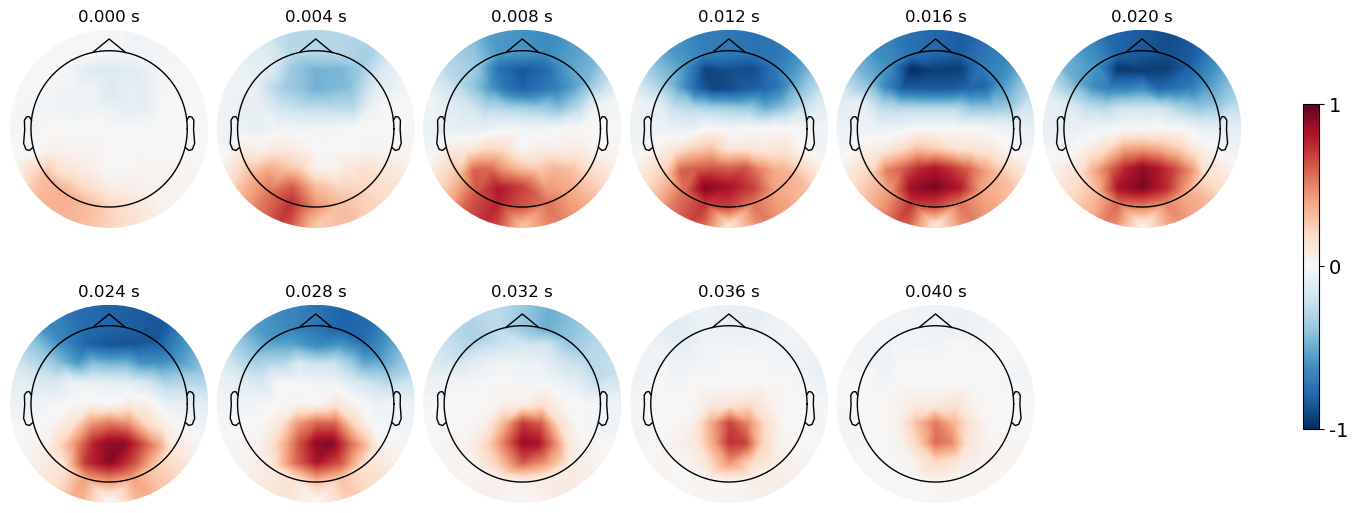

Saved consensus average figure for cluster 0.

Plotting Cluster 1 (original ID: 1) (2/12)
  Avalanches in remapped array: 56
  Original size: 56 avalanches
  Tightness: 2.865

Cluster 1 - Building consensus average from 56 avalanches
  Medoid: avalanche 9656
  Average shape: (64, 11)


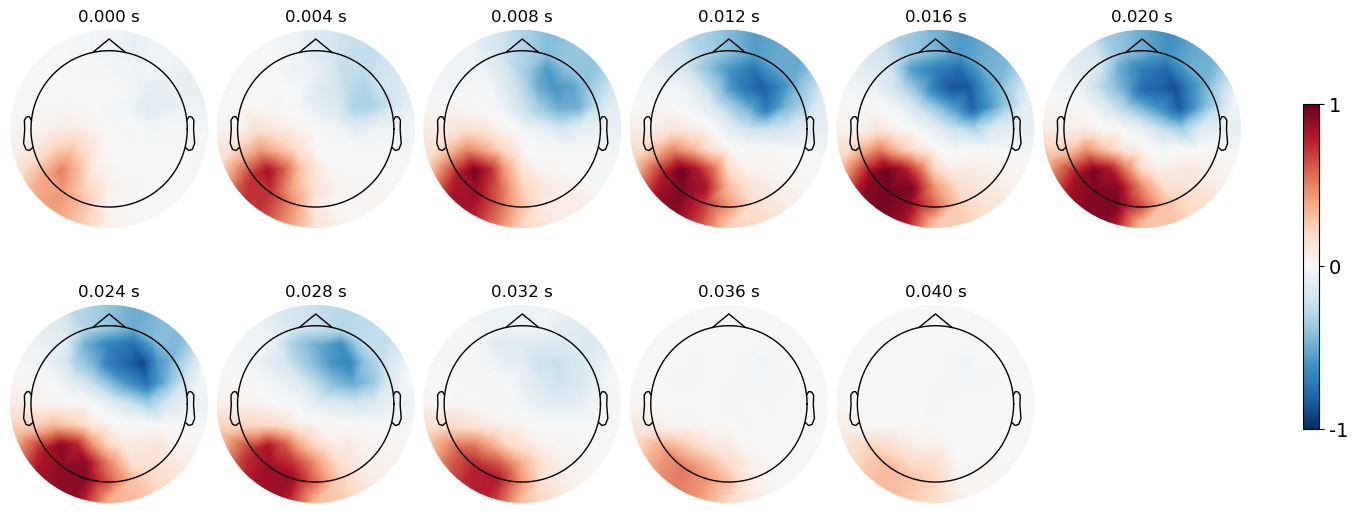

Saved consensus average figure for cluster 1.

Plotting Cluster 2 (original ID: 3) (3/12)
  Avalanches in remapped array: 46
  Original size: 46 avalanches
  Tightness: 2.914

Cluster 2 - Building consensus average from 46 avalanches
  Medoid: avalanche 6343
  Average shape: (64, 11)


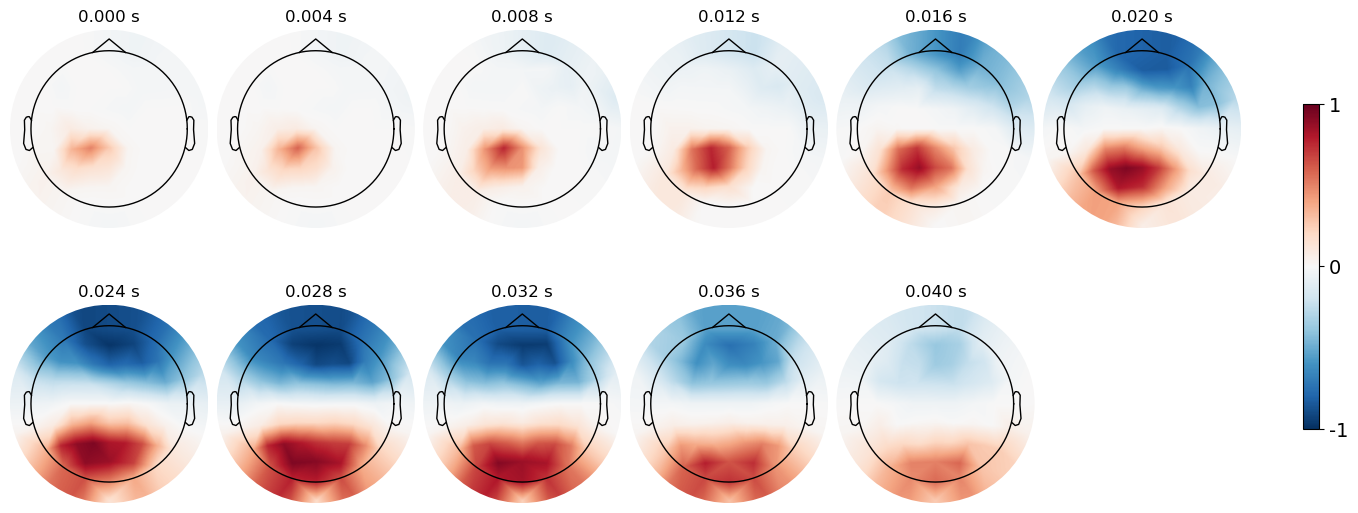

Saved consensus average figure for cluster 2.

Plotting Cluster 3 (original ID: 4) (4/12)
  Avalanches in remapped array: 33
  Original size: 33 avalanches
  Tightness: 2.935

Cluster 3 - Building consensus average from 33 avalanches
  Medoid: avalanche 6310
  Average shape: (64, 11)


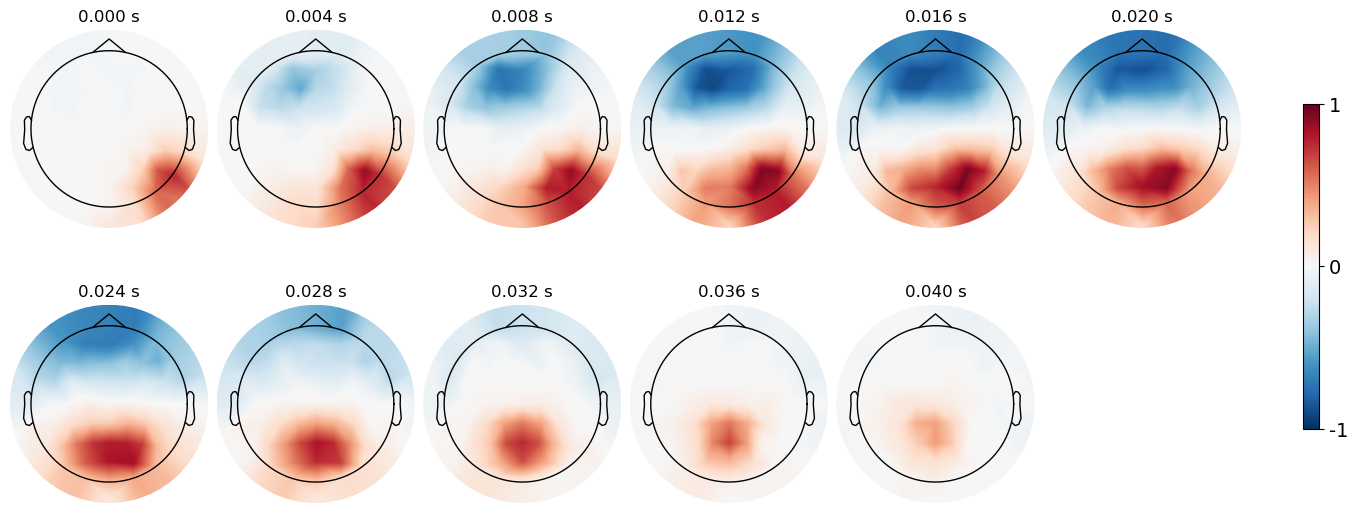

Saved consensus average figure for cluster 3.

Plotting Cluster 4 (original ID: 6) (5/12)
  Avalanches in remapped array: 47
  Original size: 47 avalanches
  Tightness: 2.842

Cluster 4 - Building consensus average from 47 avalanches
  Medoid: avalanche 5564
  Average shape: (64, 11)


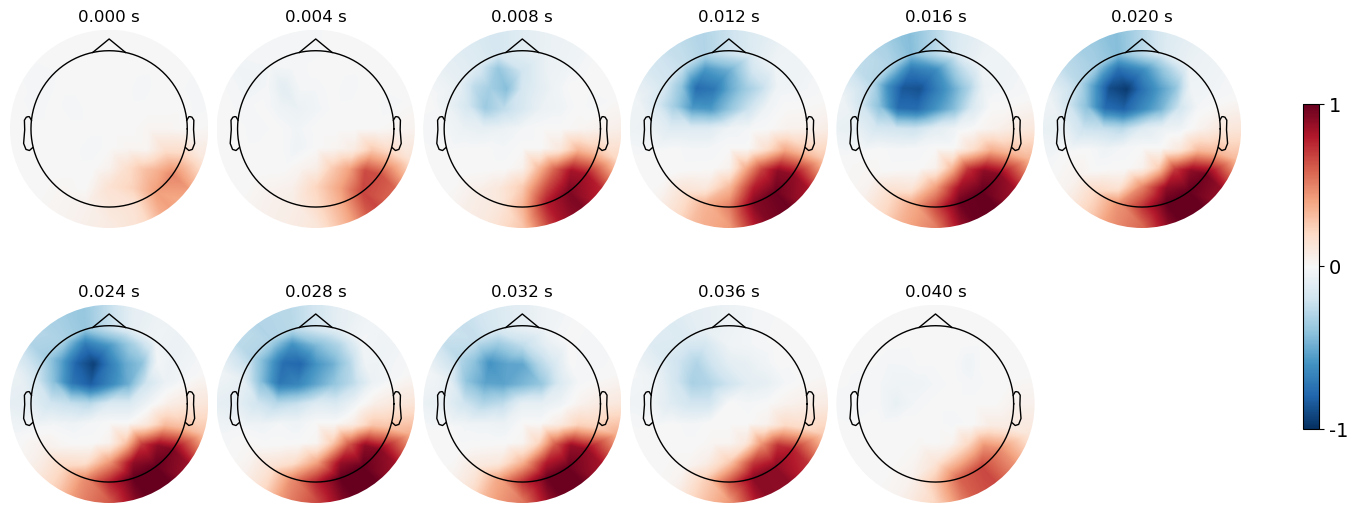

Saved consensus average figure for cluster 4.

Plotting Cluster 5 (original ID: 7) (6/12)
  Avalanches in remapped array: 46
  Original size: 46 avalanches
  Tightness: 2.982

Cluster 5 - Building consensus average from 46 avalanches
  Medoid: avalanche 8465
  Average shape: (64, 11)


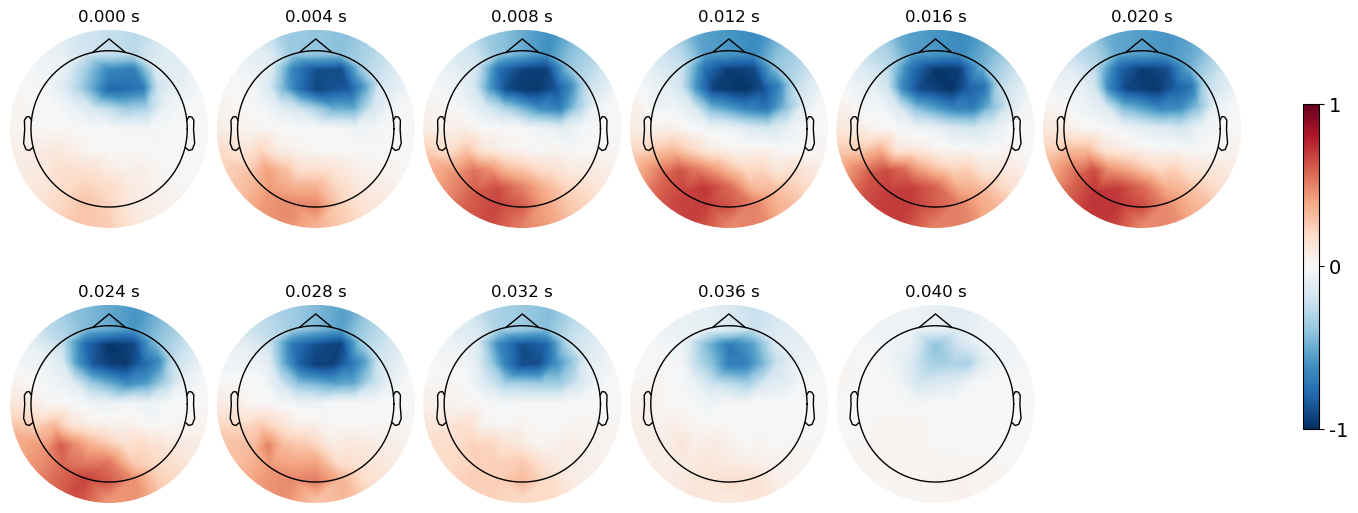

Saved consensus average figure for cluster 5.

Plotting Cluster 6 (original ID: 8) (7/12)
  Avalanches in remapped array: 43
  Original size: 43 avalanches
  Tightness: 3.036

Cluster 6 - Building consensus average from 43 avalanches
  Medoid: avalanche 9451
  Average shape: (64, 11)


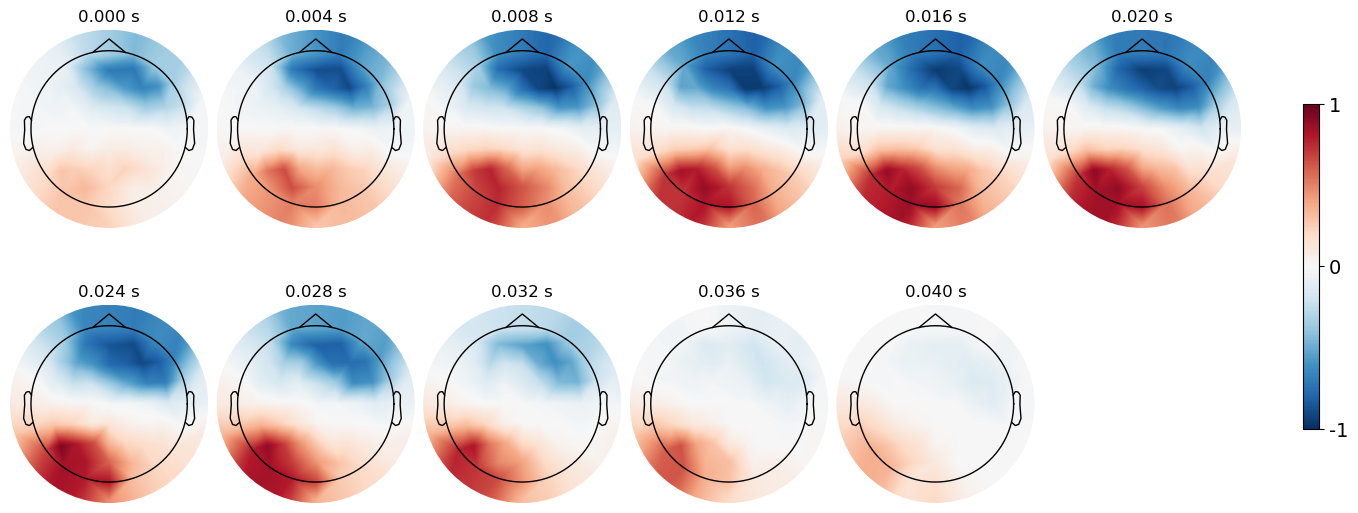

Saved consensus average figure for cluster 6.

Plotting Cluster 7 (original ID: 9) (8/12)
  Avalanches in remapped array: 39
  Original size: 39 avalanches
  Tightness: 3.120

Cluster 7 - Building consensus average from 39 avalanches
  Medoid: avalanche 1716
  Average shape: (64, 12)


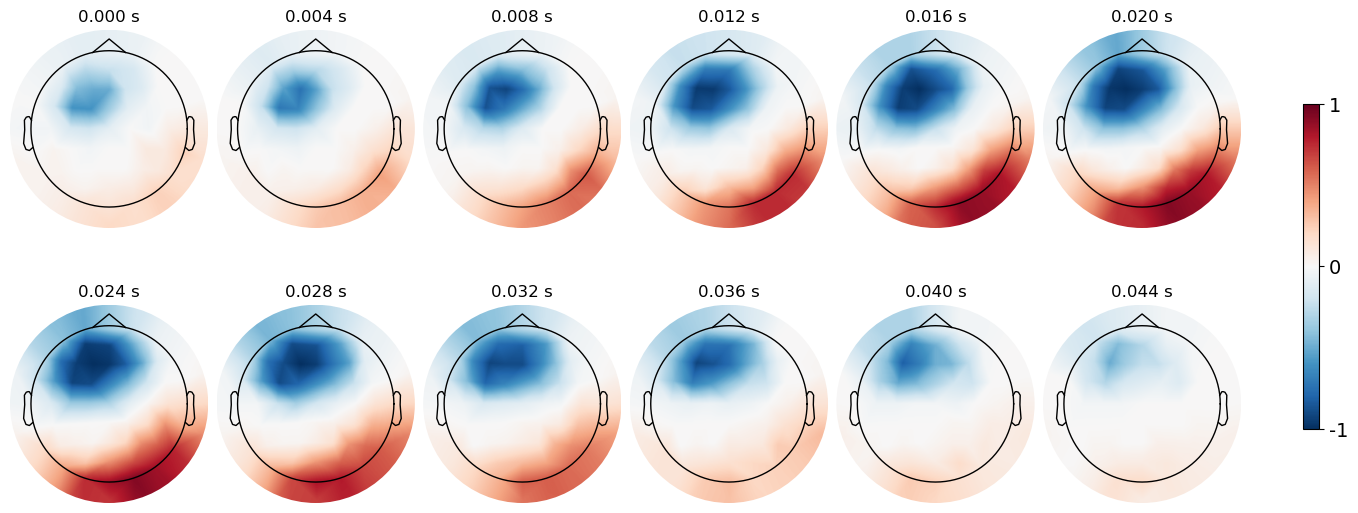

Saved consensus average figure for cluster 7.

Plotting Cluster 8 (original ID: 10) (9/12)
  Avalanches in remapped array: 42
  Original size: 42 avalanches
  Tightness: 2.929

Cluster 8 - Building consensus average from 42 avalanches
  Medoid: avalanche 5373
  Average shape: (64, 12)


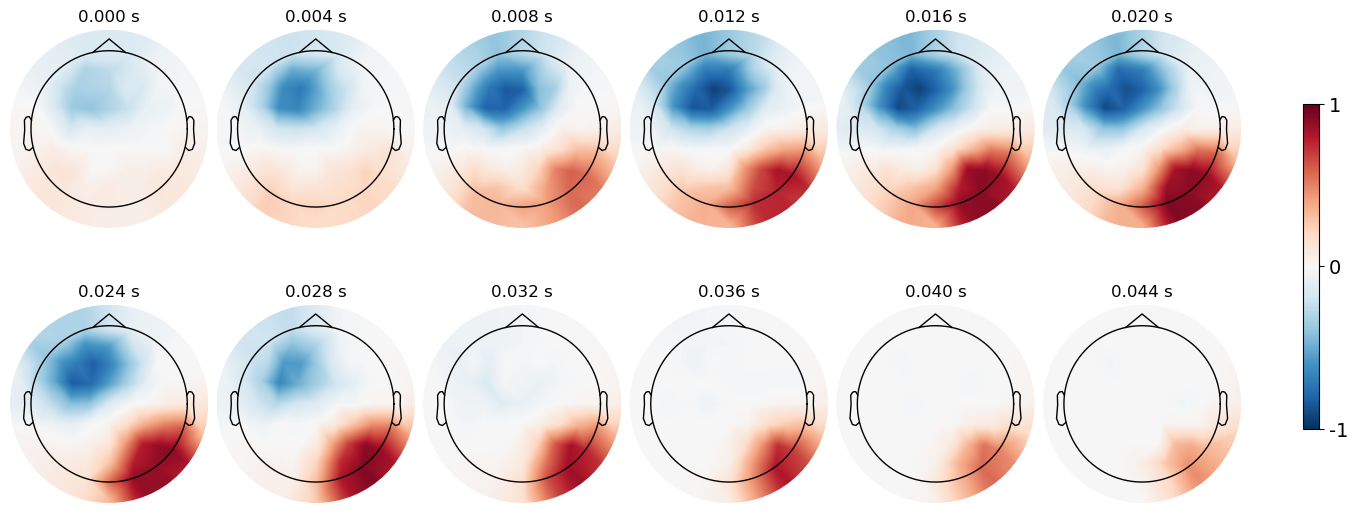

Saved consensus average figure for cluster 8.

Plotting Cluster 9 (original ID: 11) (10/12)
  Avalanches in remapped array: 30
  Original size: 30 avalanches
  Tightness: 2.776

Cluster 9 - Building consensus average from 30 avalanches
  Medoid: avalanche 2167
  Average shape: (64, 11)


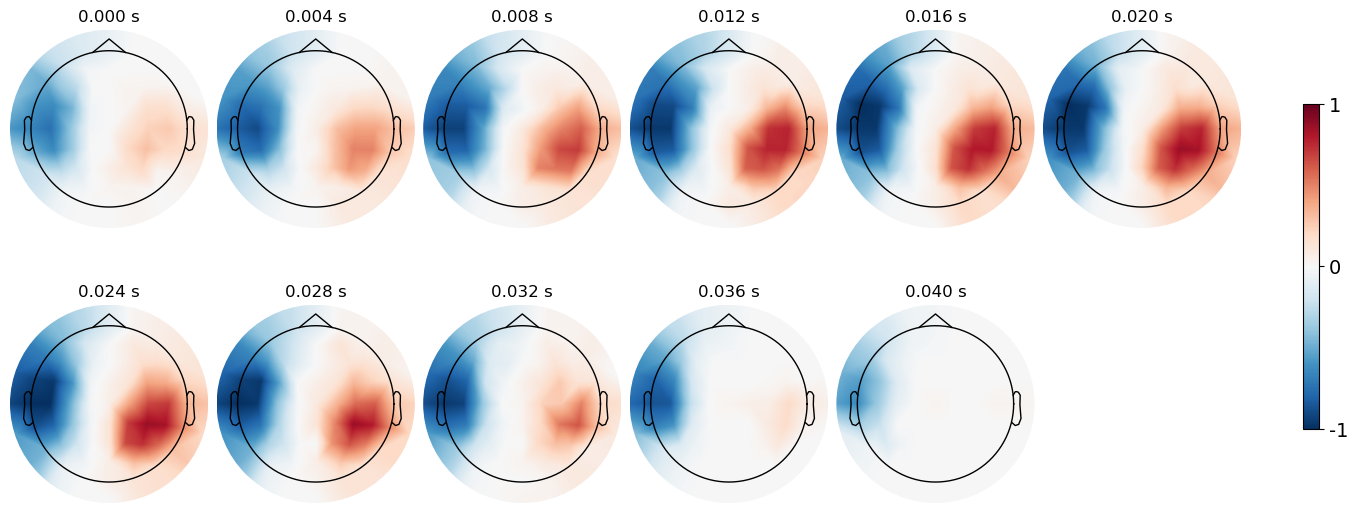

Saved consensus average figure for cluster 9.

Plotting Cluster 10 (original ID: 14) (11/12)
  Avalanches in remapped array: 60
  Original size: 60 avalanches
  Tightness: 3.026

Cluster 10 - Building consensus average from 60 avalanches
  Medoid: avalanche 7743
  Average shape: (64, 12)


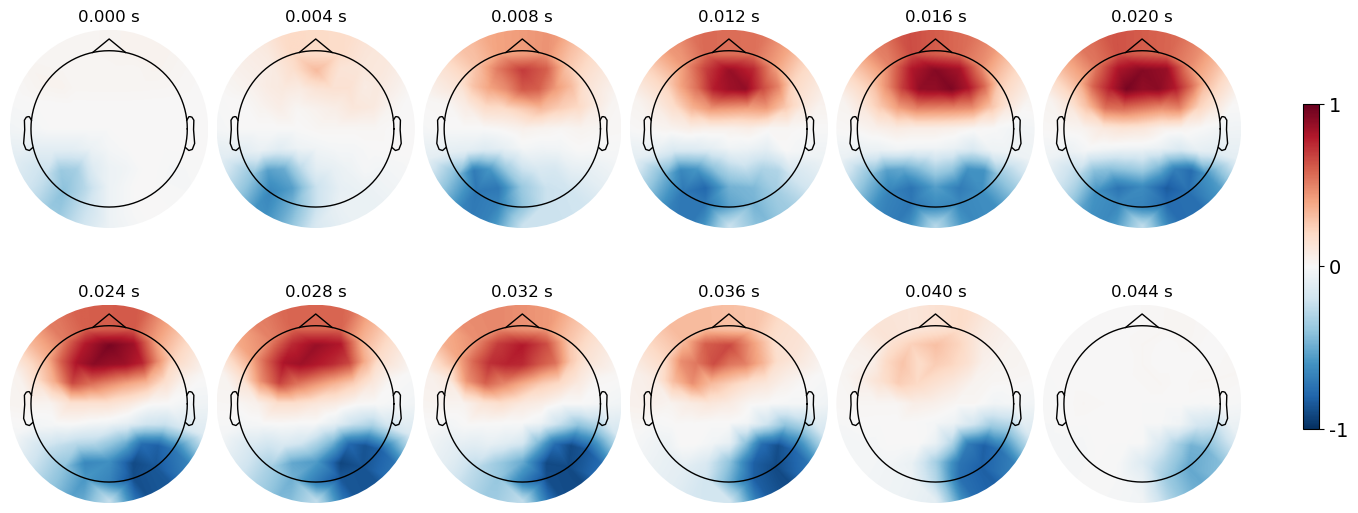

Saved consensus average figure for cluster 10.

Plotting Cluster 11 (original ID: 17) (12/12)
  Avalanches in remapped array: 100
  Original size: 100 avalanches
  Tightness: 3.142

Cluster 11 - Building consensus average from 100 avalanches
  Medoid: avalanche 4469
  Average shape: (64, 11)


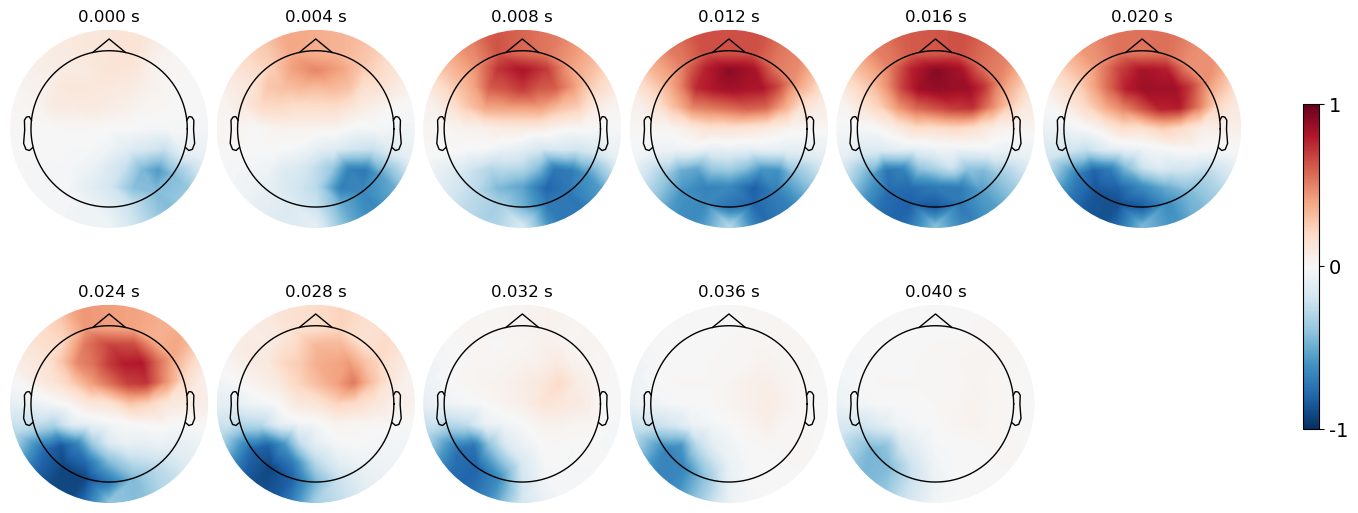

Saved consensus average figure for cluster 11.

Finished plotting all 12 clusters!


In [63]:
# Plot all clusters using REMAPPED cluster IDs
cluster_focus = cluster_info[:]  
for i, info in enumerate(cluster_focus):
    # The remapped cluster ID is simply the index i (0 to 13)
    remapped_cluster_id = i
    original_cluster_id = info['cluster_id']
    
    size = info['size']
    tightness = info['tightness']
    
    # Check if this cluster has any avalanches in clusters_remapped
    n_avalanches_in_cluster = np.sum(clusters_remapped == remapped_cluster_id)
    
    if n_avalanches_in_cluster == 0:
        print(f"\n⚠️  Skipping Cluster {remapped_cluster_id} (original: {original_cluster_id}) - no avalanches after remapping")
        continue
    
    print(f"\n{'='*60}")
    print(f"Plotting Cluster {remapped_cluster_id} (original ID: {original_cluster_id}) ({i+1}/{len(cluster_info)})")
    print(f"  Avalanches in remapped array: {n_avalanches_in_cluster}")
    print(f"  Original size: {size} avalanches")
    print(f"  Tightness: {tightness:.3f}")
    print(f"{'='*60}")
    
    # Plot using the REMAPPED cluster ID
    plot_cluster_average(
        cluster_id=remapped_cluster_id,  # Use index i (0-13)
        clusters=clusters_remapped,      # Use the remapped array
        avalanche_arrays=avalanche_arrays,
        average=cluster_averages[i], 
        medoid_idx=cluster_medoids[i],
        electrode_positions_file='/home/novicky/clean_code/electrode_positions.json',
        plot_individuals=False,
        saveit = True
    )

print(f"\nFinished plotting all {len(cluster_info)} clusters!")

In [36]:
import numpy as np
import matplotlib.pyplot as plt
import mne
from mne.channels import make_dig_montage
import json
import cv2
import os
from pathlib import Path
import tempfile

def create_cluster_video(cluster_id, clusters, avalanche_arrays, avalanche_paths, avalanche_similarity, 
                        electrode_positions_file, output_file='cluster_video.mp4', fps=10, 
                        dpi=100, figsize=(12, 8)):
    """
    Create a video from the consensus average topomap sequence.
    
    Parameters:
    -----------
    cluster_id : int
        The cluster ID to visualize
    clusters : array
        Cluster assignments for each avalanche
    avalanche_arrays : list
        List of avalanche data arrays
    avalanche_paths : list
        List of avalanche file paths
    avalanche_similarity : array
        Similarity matrix between avalanches
    electrode_positions_file : str
        Path to JSON file with electrode positions
    output_file : str
        Output video filename (default: 'cluster_video.mp4')
    fps : int
        Frames per second (default: 10)
    dpi : int
        Resolution of saved frames (default: 100)
    figsize : tuple
        Figure size in inches (default: (12, 8))
    """
    
    # Get cluster indices
    cluster_indices = np.where(clusters == cluster_id)[0]
    
    print(f"\nCluster {cluster_id} - Creating video from {len(cluster_indices)} avalanches")
    
    # Build consensus alignment (you'll need to import this function from your existing code)
    aligned, average, alignment_info, medoid_idx, consensus_count = build_consensus_alignment(
        cluster_id=cluster_id,
        clusters=clusters,
        avalanche_arrays=avalanche_arrays,
        avalanche_paths=avalanche_paths,
        similarity_clean=avalanche_similarity
    )
    
    # Get average data
    n_electrodes, n_timepoints = average.shape
    
    print(f"  Medoid: avalanche {medoid_idx}")
    print(f"  Average shape: {average.shape}")
    print(f"  Creating video with {n_timepoints} frames at {fps} fps")
    
    # Load custom electrode positions
    with open(electrode_positions_file, 'r') as f:
        electrode_data = json.load(f)
    
    channels = list(electrode_data.keys())
    
    # Create custom montage
    ch_pos = {}
    for ch in channels:
        pos = electrode_data[ch]
        ch_pos[ch] = [pos['x'], pos['y'], pos['z']]
    
    montage = make_dig_montage(ch_pos=ch_pos, coord_frame='head')
    
    # Setup MNE info
    info = mne.create_info(ch_names=channels[:n_electrodes], sfreq=250, ch_types='eeg')
    
    # Calculate consistent vlim across all timepoints
    data_max = np.max(np.abs(average))
    vlim = [-1,1]#(-data_max, data_max) if data_max > 0 else (-1, 1)
    
    # Create temporary directory for frames
    temp_dir = tempfile.mkdtemp()
    frame_files = []
    
    try:
        # Generate frames for each timepoint
        for t_idx in range(n_timepoints):
            time_point = t_idx / 250.0
            
            # Create evoked object with single timepoint
            evoked = mne.EvokedArray(average[:, [t_idx]], info, tmin=0)
            evoked.set_montage(montage)
            
            # Create figure
            fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
            
            # Plot topomap
            im, cn = mne.viz.plot_topomap(
                evoked.data[:, 0],
                evoked.info,
                axes=ax,
                show=False,
                vlim=vlim,
                cmap='RdBu_r',
                res=256,
                extrapolate='head',
                outlines='head',
                contours=0,
                sensors=True,
                sphere='auto'
            )
            
            # Add colorbar
            cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
            cbar.set_label('Activity', rotation=270, labelpad=20)
            
            # Add title with time information
            title = (f'Cluster {cluster_id} - Consensus Average\n'
                    f'Time: {time_point*1000:.1f} ms (Frame {t_idx+1}/{n_timepoints})\n'
                    f'n={len(cluster_indices)}, medoid={medoid_idx}')
            ax.set_title(title, fontsize=12, fontweight='bold', pad=20)
            
            # Save frame
            frame_file = os.path.join(temp_dir, f'frame_{t_idx:04d}.png')
            plt.savefig(frame_file, bbox_inches='tight', dpi=dpi)
            frame_files.append(frame_file)
            plt.close(fig)
            
            if (t_idx + 1) % 10 == 0:
                print(f"  Generated frame {t_idx + 1}/{n_timepoints}")
        
        print(f"\n  All {n_timepoints} frames generated. Creating video...")
        
        # Read first frame to get dimensions
        first_frame = cv2.imread(frame_files[0])
        height, width, layers = first_frame.shape
        
        # Create video writer
        fourcc = cv2.VideoWriter_fourcc(*'mp4v')
        video = cv2.VideoWriter(output_file, fourcc, fps, (width, height))
        
        # Write all frames to video
        for frame_file in frame_files:
            frame = cv2.imread(frame_file)
            video.write(frame)
        
        video.release()
        
        print(f"\n✓ Video saved to: {output_file}")
        print(f"  Duration: {n_timepoints/fps:.2f} seconds")
        print(f"  Resolution: {width}x{height}")
        
    finally:
        # Cleanup temporary files
        for frame_file in frame_files:
            if os.path.exists(frame_file):
                os.remove(frame_file)
        os.rmdir(temp_dir)


def create_individual_avalanche_video(avalanche_idx, avalanche_arrays, electrode_positions_file,
                                     output_file='avalanche_video.mp4', fps=10, dpi=100, figsize=(12, 8)):
    """
    Create a video from a single avalanche.
    
    Parameters:
    -----------
    avalanche_idx : int
        Index of the avalanche to visualize
    avalanche_arrays : list
        List of avalanche data arrays
    electrode_positions_file : str
        Path to JSON file with electrode positions
    output_file : str
        Output video filename
    fps : int
        Frames per second (default: 10)
    dpi : int
        Resolution of saved frames (default: 100)
    figsize : tuple
        Figure size in inches (default: (12, 8))
    """
    
    avalanche_data = avalanche_arrays[avalanche_idx]
    n_electrodes, n_timepoints = avalanche_data.shape
    
    print(f"\nCreating video for avalanche {avalanche_idx}")
    print(f"  Shape: {avalanche_data.shape}")
    print(f"  Creating video with {n_timepoints} frames at {fps} fps")
    
    # Load custom electrode positions
    with open(electrode_positions_file, 'r') as f:
        electrode_data = json.load(f)
    
    channels = list(electrode_data.keys())
    
    # Create custom montage
    ch_pos = {}
    for ch in channels:
        pos = electrode_data[ch]
        ch_pos[ch] = [pos['x'], pos['y'], pos['z']]
    
    montage = make_dig_montage(ch_pos=ch_pos, coord_frame='head')
    
    # Setup MNE info
    info = mne.create_info(ch_names=channels[:n_electrodes], sfreq=250, ch_types='eeg')
    
    # Calculate consistent vlim
    data_max = np.max(np.abs(avalanche_data))
    vlim = [-1,1]#(-data_max, data_max) if data_max > 0 else (-1, 1)
    
    # Create temporary directory for frames
    temp_dir = tempfile.mkdtemp()
    frame_files = []
    
    try:
        # Generate frames for each timepoint
        for t_idx in range(n_timepoints):
            time_point = t_idx / 250.0
            
            # Create evoked object with single timepoint
            evoked = mne.EvokedArray(avalanche_data[:, [t_idx]], info, tmin=0)
            evoked.set_montage(montage)
            
            # Create figure
            fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
            
            # Plot topomap
            im, cn = mne.viz.plot_topomap(
                evoked.data[:, 0],
                evoked.info,
                axes=ax,
                show=False,
                vlim=vlim,
                cmap='RdBu_r',
                res=256,
                extrapolate='head',
                outlines='head',
                contours=0,
                sensors=True,
                sphere='auto'
            )
            
            # Add colorbar
            cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
            cbar.set_label('Activity', rotation=270, labelpad=20)
            
            # Add title with time information
            title = (f'Avalanche {avalanche_idx}\n'
                    f'Time: {time_point*1000:.1f} ms (Frame {t_idx+1}/{n_timepoints})')
            ax.set_title(title, fontsize=12, fontweight='bold', pad=20)
            
            # Save frame
            frame_file = os.path.join(temp_dir, f'frame_{t_idx:04d}.png')
            plt.savefig(frame_file, bbox_inches='tight', dpi=dpi)
            frame_files.append(frame_file)
            plt.close(fig)
            
            if (t_idx + 1) % 10 == 0:
                print(f"  Generated frame {t_idx + 1}/{n_timepoints}")
        
        print(f"\n  All {n_timepoints} frames generated. Creating video...")
        
        # Read first frame to get dimensions
        first_frame = cv2.imread(frame_files[0])
        height, width, layers = first_frame.shape
        
        # Create video writer
        fourcc = cv2.VideoWriter_fourcc(*'mp4v')
        video = cv2.VideoWriter(output_file, fourcc, fps, (width, height))
        
        # Write all frames to video
        for frame_file in frame_files:
            frame = cv2.imread(frame_file)
            video.write(frame)
        
        video.release()
        
        print(f"\n✓ Video saved to: {output_file}")
        print(f"  Duration: {n_timepoints/fps:.2f} seconds")
        print(f"  Resolution: {width}x{height}")
        
    finally:
        # Cleanup temporary files
        for frame_file in frame_files:
            if os.path.exists(frame_file):
                os.remove(frame_file)
        os.rmdir(temp_dir)


In [37]:
# Plot all clusters (they're already sorted by tightness - best first)
cluster_averages = []
cluster_focus = cluster_info
for i, info in enumerate(cluster_info):
    # Use remapped cluster ID (sequential 0-13)
    remapped_cluster_id = i
    original_cluster_id = info['cluster_id']
    
    # Check if this cluster has any avalanches
    n_avalanches_in_cluster = np.sum(clusters_remapped == remapped_cluster_id)
    
    if n_avalanches_in_cluster == 0:
        print(f"⚠️  Skipping Cluster {remapped_cluster_id} (original: {original_cluster_id}) - no avalanches")
        continue
    
    print(f"Creating video for Cluster {remapped_cluster_id} (original ID: {original_cluster_id})")
    print(f"  {n_avalanches_in_cluster} avalanches")

    create_cluster_video(
        cluster_id=remapped_cluster_id,  # Use remapped ID (0-13)
        clusters=clusters_remapped,
        avalanche_arrays=avalanche_arrays,
        avalanche_paths=avalanche_paths,
        avalanche_similarity=avalanche_similarity,
        electrode_positions_file='electrode_positions.json',
        output_file=f'cluster_{remapped_cluster_id}_consensus.mp4',  # Use remapped ID in filename
        fps=5,
        dpi=150
    )

Creating video for Cluster 0 (original ID: 0)
  35 avalanches

Cluster 0 - Creating video from 35 avalanches

Cluster 0: 35 avalanches
Avalanche indices: [  405   571  1177  1455  1584  1775  2497  3845  4003  4714  5050  5100
  5177  5180  5213  5219  5229  5334  5349  5356  5498  6079  6698  7295
  7723  8543  8561  8652  9207  9212  9562  9563  9696  9921 10090]

Medoid: avalanche 9921
  Shape: (64, 11)
  Length: 11 time steps
  Avg distance to others: 2.202

Warping avalanches to medoid timeline...
  Avalanche 9921 (medoid): identity mapping
  Medoid: avalanche 9921
  Average shape: (64, 11)
  Creating video with 11 frames at 5 fps
  Generated frame 10/11

  All 11 frames generated. Creating video...

✓ Video saved to: cluster_0_consensus.mp4
  Duration: 2.20 seconds
  Resolution: 1176x1082
Creating video for Cluster 1 (original ID: 1)
  56 avalanches

Cluster 1 - Creating video from 56 avalanches

Cluster 1: 56 avalanches
Avalanche indices: [  263   555  1512  1676  1723  2416  33

In [38]:
import cv2
import numpy as np
import os
import re
from pathlib import Path

def create_title_frame(text, width, height, duration_seconds=2, fps=30):
    """
    Create a title frame with text.
    
    Parameters:
    -----------
    text : str
        Text to display on the title frame
    width : int
        Width of the frame
    height : int
        Height of the frame
    duration_seconds : int
        How long to display the title (default: 2 seconds)
    fps : int
        Frames per second
        
    Returns:
    --------
    list of frames
    """
    num_frames = int(duration_seconds * fps)
    frames = []
    
    for _ in range(num_frames):
        # Create black frame
        frame = np.zeros((height, width, 3), dtype=np.uint8)
        
        # Add text
        font = cv2.FONT_HERSHEY_SIMPLEX
        font_scale = 3
        thickness = 8  # Thicker for bold appearance
        
        # Get text size to center it
        (text_width, text_height), baseline = cv2.getTextSize(text, font, font_scale, thickness)
        
        # Calculate position to center text
        x = (width - text_width) // 2
        y = (height + text_height) // 2
        
        # Draw text in white
        cv2.putText(frame, text, (x, y), font, font_scale, (255, 255, 255), thickness, cv2.LINE_AA)
        
        frames.append(frame)
    
    return frames


def combine_cluster_videos(input_dir, output_file='combined_clusters.mp4', title_duration=2):
    """
    Combine all cluster videos in a directory with title frames.
    
    Parameters:
    -----------
    input_dir : str
        Directory containing cluster_X_consensus.mp4 files
    output_file : str
        Output filename for combined video
    title_duration : int
        Duration of title frames in seconds (default: 2)
    """
    
    input_path = Path(input_dir)
    
    # Find all cluster videos and sort by cluster ID
    video_files = []
    for file in input_path.glob('cluster_*_consensus.mp4'):
        # Extract cluster ID from filename
        match = re.search(r'cluster_(\d+)_consensus\.mp4', file.name)
        if match:
            cluster_id = int(match.group(1))
            video_files.append((cluster_id, file))
    
    # Sort by cluster ID
    video_files.sort(key=lambda x: x[0])
    
    if not video_files:
        print(f"No cluster videos found in {input_dir}")
        return
    
    print(f"Found {len(video_files)} cluster videos:")
    for cluster_id, file in video_files:
        print(f"  Cluster {cluster_id}: {file.name}")
    
    # Get video properties from first video
    first_video = cv2.VideoCapture(str(video_files[0][1]))
    width = int(first_video.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(first_video.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = first_video.get(cv2.CAP_PROP_FPS)
    first_video.release()
    
    print(f"\nVideo properties: {width}x{height} @ {fps} fps")
    print(f"Title duration: {title_duration} seconds")
    
    # Create output video writer
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    output_path = os.path.join(input_dir, output_file)
    out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))
    
    total_frames = 0
    
    # Process each cluster video
    for i, (cluster_id, video_file) in enumerate(video_files):
        print(f"\nProcessing Cluster {cluster_id} ({i+1}/{len(video_files)})...")
        
        # Add title frame
        title_text = f"Cluster {cluster_id}"
        print(f"  Adding title frame: '{title_text}'")
        title_frames = create_title_frame(title_text, width, height, title_duration, int(fps))
        
        for frame in title_frames:
            out.write(frame)
            total_frames += 1
        
        # Add cluster video
        print(f"  Adding video content from {video_file.name}")
        cap = cv2.VideoCapture(str(video_file))
        
        frame_count = 0
        while True:
            ret, frame = cap.read()
            if not ret:
                break
            
            # Resize frame if necessary
            if frame.shape[1] != width or frame.shape[0] != height:
                frame = cv2.resize(frame, (width, height))
            
            out.write(frame)
            total_frames += 1
            frame_count += 1
        
        cap.release()
        print(f"  Added {frame_count} frames from cluster video")
    
    out.release()
    
    total_duration = total_frames / fps
    print(f"\n✓ Combined video saved to: {output_path}")
    print(f"  Total frames: {total_frames}")
    print(f"  Total duration: {total_duration:.2f} seconds ({total_duration/60:.2f} minutes)")
    print(f"  Combined {len(video_files)} cluster videos")


if __name__ == "__main__":
    # Usage
    input_directory = "/home/novicky/clean_code"
    
    combine_cluster_videos(
        input_dir=input_directory,
        output_file='all_clusters_combined_poles.mp4',
        title_duration=2
    )

Found 12 cluster videos:
  Cluster 0: cluster_0_consensus.mp4
  Cluster 1: cluster_1_consensus.mp4
  Cluster 2: cluster_2_consensus.mp4
  Cluster 3: cluster_3_consensus.mp4
  Cluster 4: cluster_4_consensus.mp4
  Cluster 5: cluster_5_consensus.mp4
  Cluster 6: cluster_6_consensus.mp4
  Cluster 7: cluster_7_consensus.mp4
  Cluster 8: cluster_8_consensus.mp4
  Cluster 9: cluster_9_consensus.mp4
  Cluster 10: cluster_10_consensus.mp4
  Cluster 11: cluster_11_consensus.mp4

Video properties: 1176x1082 @ 5.0 fps
Title duration: 2 seconds

Processing Cluster 0 (1/12)...
  Adding title frame: 'Cluster 0'
  Adding video content from cluster_0_consensus.mp4
  Added 11 frames from cluster video

Processing Cluster 1 (2/12)...
  Adding title frame: 'Cluster 1'
  Adding video content from cluster_1_consensus.mp4
  Added 11 frames from cluster video

Processing Cluster 2 (3/12)...
  Adding title frame: 'Cluster 2'
  Adding video content from cluster_2_consensus.mp4
  Added 11 frames from cluster vid